In [1]:
import gymnasium as gym
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque, namedtuple
import matplotlib.pyplot as plt
from itertools import count

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")
print("Using device:", device)

Using device: cpu


In [2]:
env = gym.make("LunarLander-v3")
env.reset(seed=SEED)

state_dim  = env.observation_space.shape[0]
action_dim = env.action_space.n

print(f"State dimension: {state_dim}")
print(f"Action dimension: {action_dim}")

State dimension: 8
Action dimension: 4


In [3]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, action_dim),
        )

    def forward(self, x):
        return self.net(x)

In [4]:
Transition = namedtuple("Transition",
                        ("state", "action", "reward", "next_state", "done"))

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, *args):
        self.buffer.append(Transition(*args))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        return Transition(*zip(*batch))

    def __len__(self):
        return len(self.buffer)

In [5]:
class DQNAgent:
    def __init__(self,
                 state_dim,
                 action_dim,
                 lr=5e-4,
                 gamma=0.99,
                 buffer_size=100_000,
                 batch_size=128,
                 tau=0.005,
                 eps_start=1.0,
                 eps_end=0.05,
                 eps_decay=0.995):
        self.action_dim  = action_dim
        self.gamma       = gamma
        self.batch_size  = batch_size
        self.tau         = tau
        self.eps         = eps_start
        self.eps_end     = eps_end
        self.eps_decay   = eps_decay

        self.policy_net = QNetwork(state_dim, action_dim).to(device)
        self.target_net = QNetwork(state_dim, action_dim).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.memory = ReplayBuffer(buffer_size)

    def select_action(self, state, evaluate=False):
        if evaluate or random.random() > self.eps:
            with torch.no_grad():
                s = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
                return int(self.policy_net(s).argmax().item())
        return random.randrange(self.action_dim)

    def optimize(self):
        if len(self.memory) < self.batch_size:
            return None

        t = self.memory.sample(self.batch_size)
        states      = torch.tensor(np.array(t.state), dtype=torch.float32, device=device)
        actions     = torch.tensor(t.action, dtype=torch.long, device=device).unsqueeze(1)
        rewards     = torch.tensor(t.reward, dtype=torch.float32, device=device).unsqueeze(1)
        next_states = torch.tensor(np.array(t.next_state), dtype=torch.float32, device=device)
        dones       = torch.tensor(t.done, dtype=torch.float32, device=device).unsqueeze(1)

        q_values = self.policy_net(states).gather(1, actions)

        with torch.no_grad():
            next_q = self.target_net(next_states).max(1, keepdim=True)[0]
            target = rewards + self.gamma * next_q * (1 - dones)

        loss = F.smooth_l1_loss(q_values, target)

        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 10.0)
        self.optimizer.step()

        return loss.item()

    def update_target(self):
        for tp, pp in zip(self.target_net.parameters(), self.policy_net.parameters()):
            tp.data.copy_(self.tau * pp.data + (1.0 - self.tau) * tp.data)

    def decay_epsilon(self):
        self.eps = max(self.eps_end, self.eps * self.eps_decay)

In [6]:
NUM_EPISODES       = 1000
SOLVE_THRESHOLD    = 200
TARGET_AVG_REWARD  = 200
PRINT_EVERY        = 20

agent = DQNAgent(state_dim, action_dim)
reward_history = []
avg_history    = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    episode_reward = 0.0

    for step in count():
        action = agent.select_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        agent.memory.push(state, action, reward, next_state, float(done))
        agent.optimize()
        agent.update_target()

        state = next_state
        episode_reward += reward

        if done:
            break

    agent.decay_epsilon()
    reward_history.append(episode_reward)

    if len(reward_history) >= 100:
        avg = np.mean(reward_history[-100:])
    else:
        avg = np.mean(reward_history)
    avg_history.append(avg)

    if episode % PRINT_EVERY == 0:
        print(f"Episode {episode:4d} | Reward: {episode_reward:7.2f} | "
              f"100-Ep Avg: {avg:7.2f} | Epsilon: {agent.eps:.3f}")

    if avg >= TARGET_AVG_REWARD:
        print(f"\n✅ Solved in episode {episode} with 100-ep average {avg:.2f}!")
        break

Episode   20 | Reward: -154.03 | 100-Ep Avg: -138.26 | Epsilon: 0.905
Episode   40 | Reward:  -83.97 | 100-Ep Avg: -122.41 | Epsilon: 0.818
Episode   60 | Reward:  -83.33 | 100-Ep Avg: -114.89 | Epsilon: 0.740
Episode   80 | Reward:  -80.42 | 100-Ep Avg: -103.10 | Epsilon: 0.670
Episode  100 | Reward:   21.50 | 100-Ep Avg:  -94.40 | Epsilon: 0.606
Episode  120 | Reward:  -11.55 | 100-Ep Avg:  -75.21 | Epsilon: 0.548
Episode  140 | Reward:  -24.78 | 100-Ep Avg:  -63.95 | Epsilon: 0.496
Episode  160 | Reward:   59.83 | 100-Ep Avg:  -49.19 | Epsilon: 0.448
Episode  180 | Reward:    6.48 | 100-Ep Avg:  -38.81 | Epsilon: 0.406
Episode  200 | Reward:   44.29 | 100-Ep Avg:  -27.70 | Epsilon: 0.367
Episode  220 | Reward:   52.71 | 100-Ep Avg:  -20.29 | Epsilon: 0.332
Episode  240 | Reward:  121.74 | 100-Ep Avg:   -2.46 | Epsilon: 0.300
Episode  260 | Reward:  188.51 | 100-Ep Avg:   18.15 | Epsilon: 0.272
Episode  280 | Reward:  -30.31 | 100-Ep Avg:   38.08 | Epsilon: 0.246
Episode  300 | Rewar

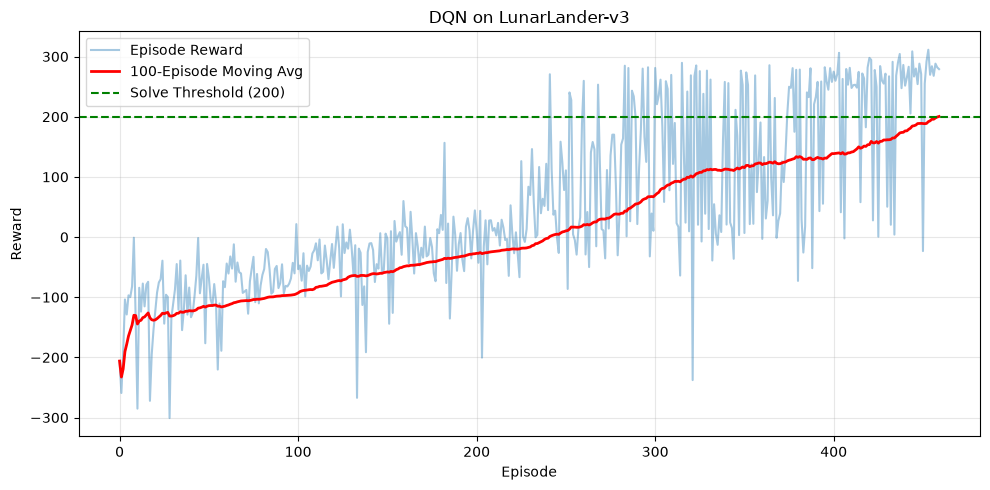

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(reward_history, label="Episode Reward", alpha=0.4)
plt.plot(avg_history, label="100-Episode Moving Avg", color="red", linewidth=2)
plt.axhline(y=TARGET_AVG_REWARD, color="green", linestyle="--", label="Solve Threshold (200)")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN on LunarLander-v3")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
torch.save(agent.policy_net.state_dict(), "lunarlander_dqn.pth")
print("Model saved to lunarlander_dqn.pth")

Model saved to lunarlander_dqn.pth


In [9]:
# Load model (optional if continuing in same session)
# agent.policy_net.load_state_dict(torch.load("lunarlander_dqn.pth", map_location=device))
agent.policy_net.eval()

eval_env = gym.make("LunarLander-v3", render_mode=None)
eval_rewards = []

for ep in range(20):
    state, _ = eval_env.reset()
    total_reward = 0.0
    done = False
    while not done:
        action = agent.select_action(state, evaluate=True)
        state, reward, terminated, truncated, _ = eval_env.step(action)
        total_reward += reward
        done = terminated or truncated
    eval_rewards.append(total_reward)
    print(f"Eval Episode {ep+1:2d}: Reward = {total_reward:.2f}")

print(f"\nAverage evaluation reward over 20 episodes: {np.mean(eval_rewards):.2f}")
eval_env.close()

Eval Episode  1: Reward = 118.39
Eval Episode  2: Reward = 259.63
Eval Episode  3: Reward = 263.25
Eval Episode  4: Reward = 275.67
Eval Episode  5: Reward = 257.30
Eval Episode  6: Reward = 239.00
Eval Episode  7: Reward = 281.29
Eval Episode  8: Reward = 271.55
Eval Episode  9: Reward = 275.63
Eval Episode 10: Reward = 262.61
Eval Episode 11: Reward = 267.80
Eval Episode 12: Reward = 271.08
Eval Episode 13: Reward = 258.40
Eval Episode 14: Reward = 273.76
Eval Episode 15: Reward = 258.72
Eval Episode 16: Reward = 272.21
Eval Episode 17: Reward = 283.16
Eval Episode 18: Reward = 273.60
Eval Episode 19: Reward = 289.98
Eval Episode 20: Reward = 270.78

Average evaluation reward over 20 episodes: 261.19



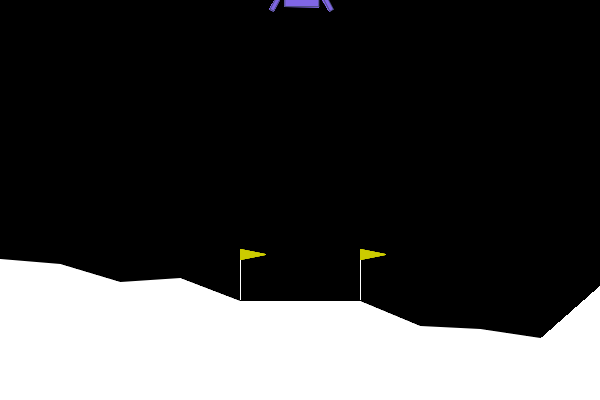

In [10]:
import base64
from IPython.display import HTML

def record_episode(env_id="LunarLander-v3", fps=30):
    rec_env = gym.make(env_id, render_mode="rgb_array")
    state, _ = rec_env.reset(seed=SEED)
    frames = []
    done = False

    while not done:
        action = agent.select_action(state, evaluate=True)
        state, _, terminated, truncated, _ = rec_env.step(action)
        frame = rec_env.render()
        if frame is not None:
            frames.append(frame)
        done = terminated or truncated

    rec_env.close()

    # Encode frames as an animated GIF (in-memory, no file written)
    import io
    from PIL import Image

    images = [Image.fromarray(f) for f in frames]
    buf = io.BytesIO()
    images[0].save(
        buf,
        format="GIF",
        save_all=True,
        append_images=images[1:],
        duration=int(1000 / fps),
        loop=0,
    )
    buf.seek(0)
    b64 = base64.b64encode(buf.read()).decode("utf-8")

    return HTML(
        f'<img src="data:image/gif;base64,{b64}" '
        f'style="display:block;margin:auto;max-width:600px;">'
    )

record_episode()